# Error and Significance Level
---

## Experiment: exact size and power of a binomial test.

In [1]:
import numpy as np
from scipy.stats import binom

n = 10
cutoff = 9

# Reject H0 if the number of heads is at least 9.
size = binom.sf(cutoff - 1, n, p=0.5)
size_if_eight = binom.sf(7, n, p=0.5)
power = binom.sf(cutoff - 1, n, p=0.8)
type_ii_error = 1 - power

print(f"Actual test size: {size:.5f}")
print(f"Size with cutoff 8: {size_if_eight:.5f}")
print(f"Power at p=0.8: {power:.5f}")
print(f"Type II error at p=0.8: {type_ii_error:.5f}")

# Examine the power function for a range of true values.
for p in [0.3, 0.5, 0.6, 0.8, 1.0]:
    rejection_probability = binom.sf(cutoff - 1, n, p=p)
    print(f"p={p:.1f}: P(reject)={rejection_probability:.4f}")

# Experiment: repeat with 20 tosses and choose a level-0.05 cutoff.

Actual test size: 0.01074
Size with cutoff 8: 0.05469
Power at p=0.8: 0.37581
Type II error at p=0.8: 0.62419
p=0.3: P(reject)=0.0001
p=0.5: P(reject)=0.0107
p=0.6: P(reject)=0.0464
p=0.8: P(reject)=0.3758
p=1.0: P(reject)=1.0000


## Experiment: simulating type I error and power.

Critical sample mean: 103.2897
Simulated type I error: 0.0498
Simulated power at mu=105: 0.8051
Theoretical power: 0.8038


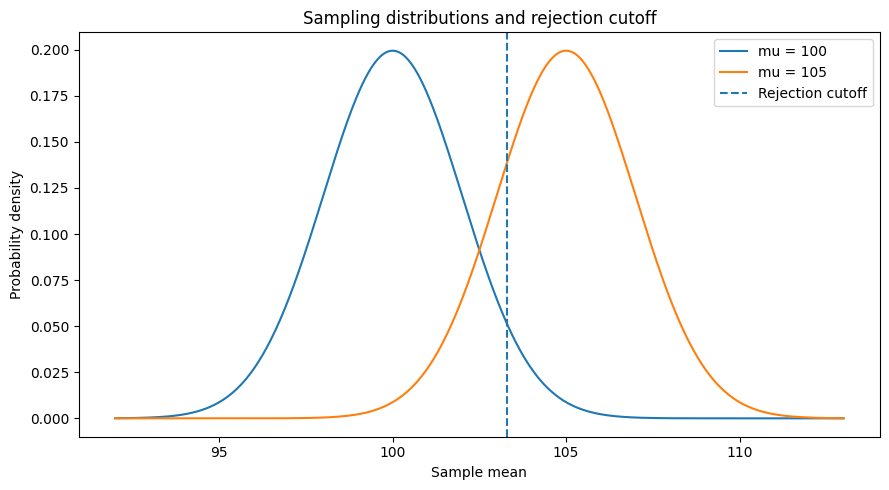

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(2026)

mu_0, sigma, n, alpha = 100, 10, 25, 0.05
standard_error = sigma / np.sqrt(n)
cutoff = mu_0 + norm.isf(alpha) * standard_error

# Each draw represents the mean of one entire study.
repetitions = 100_000
null_means = rng.normal(100, standard_error, size=repetitions)
alt_means = rng.normal(105, standard_error, size=repetitions)

empirical_size = np.mean(null_means > cutoff)
empirical_power = np.mean(alt_means > cutoff)
theoretical_power = norm.sf((cutoff - 105) / standard_error)

print(f"Critical sample mean: {cutoff:.4f}")
print(f"Simulated type I error: {empirical_size:.4f}")
print(f"Simulated power at mu=105: {empirical_power:.4f}")
print(f"Theoretical power: {theoretical_power:.4f}")

x = np.linspace(92, 113, 500)
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x, norm.pdf(x, 100, standard_error), label="mu = 100")
ax.plot(x, norm.pdf(x, 105, standard_error), label="mu = 105")
ax.axvline(cutoff, linestyle="--", label="Rejection cutoff")
ax.set_xlabel("Sample mean")
ax.set_ylabel("Probability density")
ax.set_title("Sampling distributions and rejection cutoff")
ax.legend()

fig.tight_layout()
fig.savefig(
    "../../images/sampling_distributions.png", dpi=180, bbox_inches="tight"
)
plt.show()

# Experiment: change the alternative mean from 105 to 102.

## Experiment: power curves for different sample sizes.

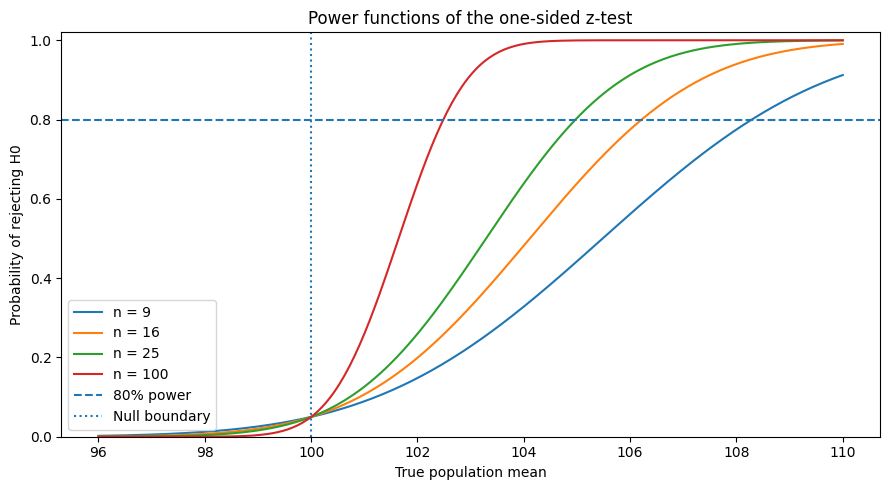

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu_0, sigma, alpha = 100, 10, 0.05
true_means = np.linspace(96, 110, 300)

fig, ax = plt.subplots(figsize=(9, 5))

for n in [9, 16, 25, 100]:
    standard_error = sigma / np.sqrt(n)
    power = norm.sf(
        norm.isf(alpha) - (true_means - mu_0) / standard_error
    )
    ax.plot(true_means, power, label=f"n = {n}")

ax.axhline(0.80, linestyle="--", label="80% power")
ax.axvline(mu_0, linestyle=":", label="Null boundary")
ax.set_xlabel("True population mean")
ax.set_ylabel("Probability of rejecting H0")
ax.set_title("Power functions of the one-sided z-test")
ax.set_ylim(0, 1.02)
ax.legend()

fig.tight_layout()
fig.savefig("../../images/power_functions.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: replace sigma=10 by sigma=20.
# How much more data is needed for similar power?

## Experiment: planning sample size.

In [4]:
from math import ceil
from scipy.stats import norm
from statsmodels.stats.power import TTestPower

alpha = 0.05
target_power = 0.80
sigma = 10
delta = 5

# One-sided z-test with known sigma.
z_alpha = norm.isf(alpha)
z_power = norm.ppf(target_power)
n_z = ((z_alpha + z_power) * sigma / delta) ** 2

print("One-sided z-test n:", ceil(n_z))

# Two-sided one-sample t-test with estimated variance.
test = TTestPower()
n_t = test.solve_power(
    effect_size=delta / sigma,
    nobs=None,
    alpha=alpha,
    power=target_power,
    alternative="two-sided",
)

n_t_rounded = ceil(n_t)
print("Two-sided t-test n:", n_t_rounded)
print("Power after rounding:", round(
    test.power(
        effect_size=delta / sigma,
        nobs=n_t_rounded,
        alpha=alpha,
        alternative="two-sided",
    ), 4
))

# Experiment: halve delta and compare the required sample sizes.

One-sided z-test n: 25
Two-sided t-test n: 34
Power after rounding: 0.8078


## Experiment: repeated testing and family-wise error.

In [5]:
import numpy as np
from scipy.stats import norm

rng = np.random.default_rng(2026)

studies = 100_000
tests_per_study = 20
alpha = 0.05

# Under the true null, the two-sided z-statistics are standard normal.
z = rng.standard_normal((studies, tests_per_study))
p_values = 2 * norm.sf(np.abs(z))

# A study has a false alarm if at least one test rejects.
any_unadjusted = np.any(p_values <= alpha, axis=1)
any_bonferroni = np.any(
    p_values <= alpha / tests_per_study, axis=1
)

print("Theoretical unadjusted FWER:", round(
    1 - (1 - alpha) ** tests_per_study, 4
))
print("Simulated unadjusted FWER:", round(
    np.mean(any_unadjusted), 4
))
print("Simulated Bonferroni FWER:", round(
    np.mean(any_bonferroni), 4
))

# Experiment: change the number of tests to 5 and 100.

Theoretical unadjusted FWER: 0.6415
Simulated unadjusted FWER: 0.6403
Simulated Bonferroni FWER: 0.0479
